Image shape: (396, 396, 3)


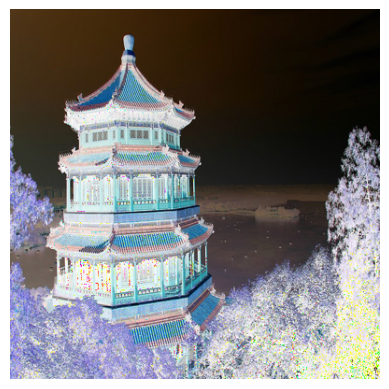

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_sample_image

# Create an RGB image using built-in sample data
from sklearn.datasets import load_sample_images

images = load_sample_images().images
img = (images[0] * 255).astype(np.uint8)

# Resize to 396 x 396
from PIL import Image
img = np.array(Image.fromarray(img).resize((396, 396)))

print("Image shape:", img.shape)
plt.imshow(img)
plt.axis("off")
plt.show()

In [6]:
from sklearn.cluster import KMeans

pixels = img.reshape(-1, 3)

kmeans = KMeans(n_clusters=16, random_state=42, n_init=10)
labels = kmeans.fit_predict(pixels)

compressed_img = kmeans.cluster_centers_[labels]
compressed_img = np.clip(compressed_img, 0, 255)
compressed_img = compressed_img.astype(np.uint8).reshape(396, 396, 3)

print("K-Means clustering completed!")

K-Means clustering completed!


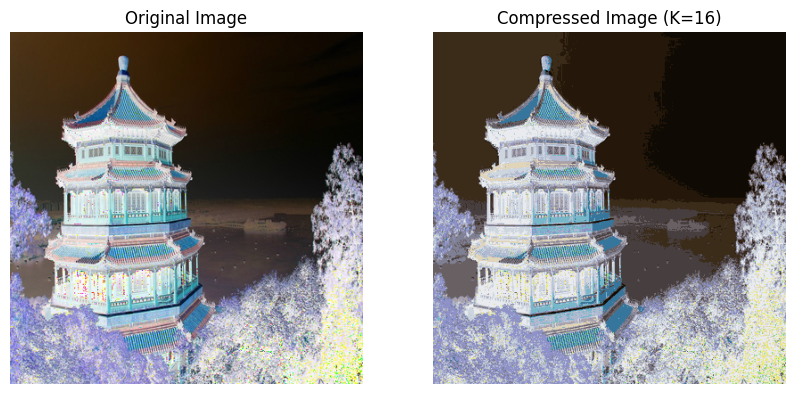

In [7]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(compressed_img)
plt.title("Compressed Image (K=16)")
plt.axis("off")

plt.show()

In [8]:
from PIL import Image

Image.fromarray(compressed_img).save("compressed_image.png")
print("Saved as compressed_image.png")

Saved as compressed_image.png
